# Business Structure and Comparable-Company Evaluation

**Research question.** When one legal company has several lines of activity, which are separate current businesses, which are related products within one business, and which have exited? The Capital IQ company ID remains the valuation unit. This experiment adds a source-checked whole-company scope to the existing v0 peer judgment; it does not create duplicate company rows or assign a parent multiple to a division.

The analysis uses the team's `company_list_v3` snapshot, saved website pages, current v0 facets, and a fixed 40-company F10 review sample. Financial multiples enter only in the final valuation check. The split method is implemented in `v0/business_split.py`; this notebook runs and evaluates it. Sources for the grouping criteria: [IFRS 8 aggregation factors](https://www.ifrs.org/content/dam/ifrs/meetings/2017/march/cmac/ap4-ifrs8.pdf) and [Hoberg and Phillips, *Management Science* (2017)](https://pubsonline.informs.org/doi/abs/10.1287/mnsc.2016.2693).

In [1]:
from pathlib import Path
from io import BytesIO
import json
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = Path.cwd()
if not (REPO / "v0").exists():
    REPO = REPO.parent.parent
assert (REPO / "v0/business_split.py").exists(), "Run from the repository or v0/notebooks."
sys.path.insert(0, str(REPO / "v0"))
import business_split as split
import judge_comps as judge
import valuation

def repo_csv(path: str) -> pd.DataFrame:
    local = REPO / path
    if local.exists():
        return pd.read_csv(local, dtype=str, comment="#")
    blob = subprocess.run(["git", "show", f"origin/main:{path}"], cwd=REPO,
                          check=True, capture_output=True).stdout
    return pd.read_csv(BytesIO(blob), dtype=str, comment="#")

SAMPLE = ['PCTY', 'BV', 'ROAD', 'LMB', 'BRO', 'ADUS', 'DXPE', 'SLGN', 'BGS', 'WEN', 'CSL', 'AFG', 'NWSA', 'AZZ', 'BOC', 'TECH', 'PBYI', 'BLBD', 'KAI', 'DORM', 'FRPT', 'HEOL', 'UFPT', 'MSA', 'TASK', 'BUKS', 'NGS', 'ACEL', 'NRC', 'DV', 'LUCK', 'FLUT', 'CCC', 'SNFC.A', 'RYAN', 'CRVL', 'GLIB.A', 'JBHT', 'BBCP', 'BBW']
RUN = REPO / "outputs-local/research/business-structure/final-split-20261027"
FOCUSED = REPO / "outputs-local/research/business-structure/focused-split-20261027"
WEB = REPO / "outputs-local/research/business-structure/web-split-20261027"

def source_run(ticker: str) -> Path:
    if ticker in {"AZZ", "BBCP", "BUKS", "SNFC.A"}:
        if (WEB / "companies" / f"{ticker}.json").exists():
            return WEB
    if ticker in {"AFG", "NWSA"}:
        if (FOCUSED / "companies" / f"{ticker}.json").exists():
            return FOCUSED
    return RUN


## 1. Inputs and the earlier split

The previous `v0/facets.py` split mode asked the model to name unrelated businesses, then checked each against saved website pages. It could remove a line when the page did not show it; a thin page therefore made a false deletion possible. The current v0 run has `SPLIT_BUSINESSES=False` and one B1 profile per company. The historical split table contains only the companies actually processed, not 533 independent split decisions. The notebook counts those records directly.

In [2]:
companies = repo_csv("data-local/snapshots/company_list_v3_websites_fixed.csv")
current = repo_csv("outputs-local/comps/facets/tables/facets.csv")
old = repo_csv("outputs-local/comps/fill_test/knowledge_only_i_haiku/tables/facets.csv")
old_done = old[old.llm_status.eq("ok")].copy()
old_counts = old_done.groupby("IQ_COMPANY_ID").size()
old_audit = pd.DataFrame({
    "source companies": [len(companies)],
    "current v0 B1 profiles": [int(current.business_id.eq("B1").sum())],
    "historical split companies processed": [len(old_counts)],
    "historical split companies with >1 line": [int(old_counts.gt(1).sum())],
    "historical split business rows": [len(old_done)],
})
display(old_audit)
old_names = old_done[old_done.business_id.eq("B1")][["IQ_COMPANY_ID", "target_company_name"]]
display(old_counts[old_counts.gt(1)].rename("business rows").reset_index().merge(old_names))

,source companies,current v0 B1 profiles,historical split companies processed,historical split companies with >1 line,historical split business rows
0,560,533,31,5,38


,IQ_COMPANY_ID,business rows,target_company_name
0,IQ1824495444,2,SBC Medical Group Holdings Incorporated
1,IQ18671,3,Albemarle Corporation
2,IQ188196,3,The St. Joe Company
3,IQ252588,2,AZZ Inc.
4,IQ263295,2,"Consolidated Edison, Inc."


## 2. Source-bound split

The model proposes **economic business lines**, not products, brands, regions, or internal functions. It reads the whole-company facets as hypotheses and cited P/W/X source lines as evidence. A documented completed sale, spin-off, or closure removes a historical line. A split needs cited differences in offerings plus customers or operating processes. Related products remain one broad business, even when immediate workflows differ. A thin page does not delete a line; if a separate business cannot be established, the company retains one whole-company scope. The Capital IQ company ID never duplicates. Sources and raw responses are preserved per company under `outputs-local/`.

The run below is resumed from its saved results. On a new checkout, it runs the 40 fixed sample companies serially. A search API key is optional (`SERPER_API_KEY`, `BRAVE_API_KEY`, or `TAVILY_API_KEY`); fetched source pages, rather than snippets, become evidence. The saved local run also used a reviewed official-source manifest for hard cases. Search-assisted cases are identified in the per-company evidence files.

In [3]:
if not (RUN / "summary.csv").exists():
    command = [sys.executable, str(REPO / "v0/business_split.py"),
               "--tickers", *SAMPLE, "--out", str(RUN)]
    subprocess.run(command, cwd=REPO, check=True)

decisions = {t: json.loads((RUN / "companies" / f"{t}.json").read_text(encoding="utf-8"))
             for t in SAMPLE}
for ticker in ("AFG", "NWSA", "AZZ", "BBCP", "BUKS", "SNFC.A"):
    path = source_run(ticker) / "companies" / f"{ticker}.json"
    if path.exists():
        decisions[ticker] = json.loads(path.read_text(encoding="utf-8"))
summary = pd.DataFrame([
    {"ticker": t, "decision": d["company_decision"],
     "current lines": len(d.get("current", [])),
     "exited lines": len(d.get("exited", [])),
     "source gaps": len(d.get("evidence_gaps", [])),
     "business groups": len(d.get("groups", []))}
    for t, d in decisions.items()
])
display(summary)
display(summary.groupby("decision").size().rename("companies"))
assert len(decisions) == len(SAMPLE)
assert all(d["company_decision"] not in ("model_error", "processing_error") for d in decisions.values())

,ticker,decision,current lines,exited lines,source gaps,business groups
0,PCTY,one_business,1,0,0,1
1,BV,one_business,1,0,0,1
2,ROAD,one_business,1,0,0,1
3,LMB,one_business,1,0,0,1
4,BRO,one_business,4,0,3,1
5,ADUS,one_business,1,0,0,1
6,DXPE,one_business,1,0,0,1
7,SLGN,one_business,3,0,3,1
8,BGS,one_business,1,0,0,1
9,WEN,one_business,1,0,0,1


decision
multiple_businesses     7
one_business           33
Name: companies, dtype: int64

In [4]:
# These are directional source challenges, not an independently reviewed gold set.
challenge = {"PCTY": "one_business", "WEN": "one_business", "CSL": "one_business",
             "AFG": "one_business", "AZZ": "one_business",
             "NWSA": "multiple_businesses", "BOC": "multiple_businesses",
             "BBCP": "multiple_businesses", "BUKS": "multiple_businesses",
             "SNFC.A": "multiple_businesses"}
challenge_rows = pd.DataFrame([{"ticker": t, "expected": expected,
                                "observed": decisions[t]["company_decision"],
                                "match": decisions[t]["company_decision"] == expected,
                                "exited": len(decisions[t].get("exited", []))}
                               for t, expected in challenge.items()])
display(challenge_rows)
print("challenge coverage:", int(challenge_rows.observed.ne("needs_evidence").sum()), "/", len(challenge_rows))
print("matches among determined:", int(challenge_rows[challenge_rows.observed.ne("needs_evidence")]["match"].sum()))

old_overlap = old_done[old_done.business_id.eq("B1")].merge(
    companies[["IQ_COMPANY_ID", "target_ciq_ticker"]], on="IQ_COMPANY_ID")
old_overlap = old_overlap[old_overlap.target_ciq_ticker.isin(SAMPLE)]
old_compare = old_overlap[["target_ciq_ticker", "IQ_COMPANY_ID"]].copy()
old_compare["old lines"] = old_compare.IQ_COMPANY_ID.map(old_counts)
old_compare["new decision"] = old_compare.target_ciq_ticker.map(
    {t: d["company_decision"] for t, d in decisions.items()})
display(old_compare.sort_values("target_ciq_ticker"))

,ticker,expected,observed,match,exited
0,PCTY,one_business,one_business,True,0
1,WEN,one_business,one_business,True,0
2,CSL,one_business,one_business,True,3
3,AFG,one_business,one_business,True,2
4,AZZ,one_business,one_business,True,1
5,NWSA,multiple_businesses,multiple_businesses,True,0
6,BOC,multiple_businesses,multiple_businesses,True,0
7,BBCP,multiple_businesses,multiple_businesses,True,0
8,BUKS,multiple_businesses,multiple_businesses,True,0
9,SNFC.A,multiple_businesses,multiple_businesses,True,0


challenge coverage: 10 / 10
matches among determined: 10


,target_ciq_ticker,IQ_COMPANY_ID,old lines,new decision
0,ADUS,IQ1108195,1,one_business
5,AZZ,IQ252588,2,one_business
6,BGS,IQ6631173,1,one_business
16,DV,IQ707993341,1,one_business
25,NGS,IQ812576,1,one_business
27,PCTY,IQ254957567,1,one_business
11,ROAD,IQ5537074,1,one_business


**Source challenges.** [Paylocity](https://www.paylocity.com/) and [Wendy's](https://www.wendys.com/franchising/franchise-faqs) test related products. [Carlisle](https://www.carlisle.com/investors/news/press-release-details/2024/Carlisle-Companies-Completes-Sale-of-Carlisle-Interconnect-Technologies/default.aspx), [AFG](https://www.afginc.com/news-releases/news-release-details/american-financial-group-inc-announces-closing-sale-its-annuity), and [AZZ](https://investor.azz.com/2023-01-09-AZZ-Inc-Announces-Fiscal-Year-2023-Third-Quarter-Results) test completed exits. [News Corp](https://newscorp.com/news-corp-businesses-and-brands/), [Boston Omaha](https://www.bostonomaha.com/), [Concrete Pumping Holdings](https://ir.concretepumpingholdings.com/press-releases/detail/105/concrete-pumping-holdings-announces-strategic-acquisition), [Butler National](https://butlernational.com/our-businesses/), and [Security National](https://www.securitynational.com/our-roots/) test current multi-business groups. These ten cases are source challenges, not an independently labeled random sample.

## 3. Downstream v0 test

The split enters the existing step-6 peer judgment as **additional whole-company context**. The B1 facets, candidate list, model, base prompt, and valuation formula stay fixed. Each target is judged twice with the same model and candidate set: once with the original prompt and once with the split context appended. Scores, peer lists, coverage, and EV/EBITDA errors are computed on the same ten development targets. The no-matching baseline supplies an explicitly labeled estimate when either rule selects no peers.

In [5]:
candidates = repo_csv("outputs-local/comps/candidates/20261025T080854Z/candidates.csv")
candidates["z"] = pd.to_numeric(candidates.z)
candidates["similarity"] = pd.to_numeric(candidates.similarity)
universe = repo_csv("outputs-local/comps/universe/20261025T060358Z/universe.csv").set_index("IQ_COMPANY_ID")
facet_rows = current[current.business_id.eq("B1")].set_index("IQ_COMPANY_ID").fillna("")
fin = repo_csv("outputs-local/comps/universe/20261025T060358Z/financials.csv")
multiple = fin.set_index("IQ_COMPANY_ID").target_ev_to_ebitda.astype(float)
id_of = dict(zip(companies.target_ciq_ticker, companies.IQ_COMPANY_ID))

TARGETS = [t for t in ("PCTY", "WEN", "CSL", "AFG", "BOC", "NWSA",
                        "AZZ", "BBCP", "BUKS", "SNFC.A")
           if decisions[t]["company_decision"] in ("one_business", "multiple_businesses")]
PEER_RUN = REPO / "outputs-local/research/business-structure/peer-test-20261027"
MODEL = "gpt-6.1-sol"
print("paired targets:", TARGETS)

paired targets: ['PCTY', 'WEN', 'CSL', 'AFG', 'BOC', 'NWSA', 'AZZ', 'BBCP', 'BUKS', 'SNFC.A']


In [6]:
records = []
with tempfile.TemporaryDirectory(prefix="split-peers-") as workdir:
    for ticker in TARGETS:
        target = id_of[ticker]
        pool = candidates[(candidates.target.eq(target)) & (candidates.z >= 2)].copy()
        prompt, labels = judge.build_prompt(target, pool.comp.tolist(), universe, facet_rows)
        context = []
        for company_id in [target, *labels.values()]:
            t = universe.loc[company_id, "target_ciq_ticker"]
            if t not in decisions:
                continue
            d = decisions[t]
            ev_path = source_run(t) / "calls" / t / "evidence.json"
            if not ev_path.exists():
                continue
            ev = split.evm.Evidence(**json.loads(ev_path.read_text(encoding="utf-8")))
            checked = split.scope_context(d, ev)
            if checked:
                context.append(f"{universe.loc[company_id, 'target_company_name']}:\n{checked}")
        for mode, p in (("original", prompt),
                        ("split_context", prompt + "\n\nAdditional source-checked scope:\n" + "\n\n".join(context))):
            folder = PEER_RUN / ticker / mode
            folder.mkdir(parents=True, exist_ok=True)
            response = folder / "response.json"
            schema = folder / "schema.json"
            schema.write_text(json.dumps(judge.answer_schema(list(labels)), indent=2), encoding="utf-8")
            prompt_file = folder / "prompt.txt"
            if response.exists() and prompt_file.exists() and prompt_file.read_text(encoding="utf-8") != p:
                history = folder / "history"
                history.mkdir(exist_ok=True)
                response.replace(history / f"response_{len(list(history.glob('response_*.json'))) + 1}.json")
                prompt_file.replace(history / f"prompt_{len(list(history.glob('prompt_*.txt'))) + 1}.txt")
            prompt_file.write_text(p, encoding="utf-8")
            if not response.exists():
                call = split.ff.call_codex(p, folder, schema, workdir, MODEL, "low")
                if call["llm_status"] != "ok":
                    raise RuntimeError(f"{ticker}/{mode}: {call}")
            checked, issues = judge.check_answer(json.loads(response.read_text(encoding="utf-8")), labels)
            if issues:
                raise ValueError(f"{ticker}/{mode}: {issues}")
            for answer in checked:
                row = pool[pool.comp.eq(answer["comp"])].iloc[0]
                records.append({"target": target, "ticker": ticker, "mode": mode,
                                "comp": answer["comp"], "peer": row.comp_ticker,
                                "score": answer["score"], "reason": answer["reason"],
                                "similarity": row.similarity})
peer_results = pd.DataFrame(records)
display(peer_results.groupby(["ticker", "mode"]).score.agg(["sum", "count"]))
print("candidate decisions changed:", int(peer_results.pivot(index=["target", "comp"], columns="mode", values="score").dropna().diff(axis=1).iloc[:, -1].ne(0).sum()))

sum  count
ticker mode                     
AFG    original         8     22
       split_context    6     22
AZZ    original         0     14
       split_context    0     14
BBCP   original         0     14
       split_context    0     14
BOC    original         4      8
       split_context    0      8
BUKS   original         1     11
       split_context    0     11
CSL    original         3      9
       split_context    2      9
NWSA   original         4      8
       split_context    4      8
PCTY   original         4     14
       split_context    3     14
SNFC.A original         1     23
       split_context    0     23
WEN    original         0     19
       split_context    0     19

candidate decisions changed: 10


,ticker,mode,estimate,actual,comps,basis,absolute_percentage_error
3,AFG,original,9.296720,9.32444,8,matched peers,0.297279
13,AFG,split_context,9.828513,9.32444,6,matched peers,5.405933
6,AZZ,original,10.453575,6.37419,372,no-matching fallback,63.998485
16,AZZ,split_context,10.453575,6.37419,372,no-matching fallback,63.998485
7,BBCP,original,10.453575,6.94970,372,no-matching fallback,50.417644
17,BBCP,split_context,10.453575,6.94970,372,no-matching fallback,50.417644
4,BOC,original,14.999373,12.08367,4,matched peers,24.129284
14,BOC,split_context,10.423920,12.08367,372,no-matching fallback,13.735479
8,BUKS,original,14.701880,7.32328,1,matched peers,100.755399
18,BUKS,split_context,10.453575,7.32328,372,no-matching fallback,42.744440


,targets,original with peers,split with peers,original median APE,split median APE,improved targets
0,10,7,4,29.212445,32.096551,3


median APE where both methods found peers: {'original': 20.906360750997983, 'split_context': 21.742924446846544}


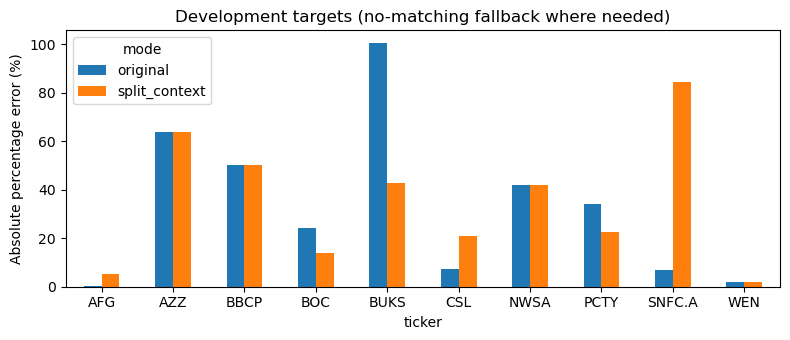

,mode,peer,score,grade
2,original,ADP,1,2
7,split_context,ADP,1,2
0,original,ALIT,1,1
5,split_context,ALIT,0,1
1,original,ASUR,1,2
6,split_context,ASUR,1,2
3,original,INTU,0,1
8,split_context,INTU,0,1
4,original,PAYC,1,2
9,split_context,PAYC,1,2


PCTY labeled candidate coverage: 5 / 11


,direct competitors retained,direct competitors labeled,adjacent firms rejected,adjacent firms labeled
mode,,,,
original,3,3,1,2
split_context,3,3,2,2


In [7]:
rows = []
training_pool = sorted(set(candidates.target))
fallback = valuation.no_matching([id_of[t] for t in TARGETS], training_pool, multiple)
for mode in ("original", "split_context"):
    good = peer_results[(peer_results["mode"] == mode) & peer_results.score.eq(1)]
    estimates = valuation.estimate(good[["target", "comp", "similarity"]], multiple,
                                   weight="similarity") if len(good) else pd.DataFrame(columns=["estimate", "comps"])
    for ticker in TARGETS:
        target = id_of[ticker]
        matched = target in estimates.index
        estimate = estimates.loc[target] if matched else fallback.loc[target]
        actual = float(multiple[target])
        rows.append({"ticker": ticker, "mode": mode,
                     "estimate": estimate["estimate"], "actual": actual,
                     "comps": int(estimate["comps"]),
                     "basis": "matched peers" if matched else "no-matching fallback",
                     "absolute_percentage_error": 100 * abs(estimate["estimate"] / actual - 1)})
valuation_check = pd.DataFrame(rows)
paired = valuation_check.pivot(index="ticker", columns="mode", values="absolute_percentage_error")
display(valuation_check.sort_values(["ticker", "mode"]))
display(pd.DataFrame({"targets": [len(paired)],
                      "original with peers": [int(valuation_check[(valuation_check['mode'] == 'original') & (valuation_check.basis == 'matched peers')].shape[0])],
                      "split with peers": [int(valuation_check[(valuation_check['mode'] == 'split_context') & (valuation_check.basis == 'matched peers')].shape[0])],
                      "original median APE": [paired.original.median() if len(paired) else np.nan],
                      "split median APE": [paired.split_context.median() if len(paired) else np.nan],
                      "improved targets": [int((paired.split_context < paired.original).sum())]}))
common_peers = valuation_check.pivot(index="ticker", columns="mode", values="basis")
common_peers = common_peers.index[(common_peers.original == 'matched peers') & (common_peers.split_context == 'matched peers')]
print("median APE where both methods found peers:",
      paired.loc[common_peers, ['original', 'split_context']].median().to_dict())
if len(paired):
    ax = paired.plot.bar(figsize=(8, 3.5), ylabel="Absolute percentage error (%)", rot=0,
                         title="Development targets (no-matching fallback where needed)")
    ax.figure.tight_layout()
    plt.show()

EVAL_OUT = REPO / "outputs-local/research/business-structure/evaluation-20261027"
EVAL_OUT.mkdir(parents=True, exist_ok=True)
summary.to_csv(EVAL_OUT / "company_decisions.csv", index=False)
peer_results.to_csv(EVAL_OUT / "peer_judgments.csv", index=False)
valuation_check.to_csv(EVAL_OUT / "valuation_comparison.csv", index=False)

# Riya's prespecified PCTY labels are useful for a narrow check; other team
# review templates have blank grades and cannot be scored as human judgments.
labels = repo_csv("pre-v0/scraps/comps_first_pass/peer_labels.csv")
labels = labels[labels.target.eq("PCTY")].copy()
labels["grade"] = pd.to_numeric(labels.grade)
pcty = peer_results[peer_results.ticker.eq("PCTY")].merge(
    labels[["peer", "grade"]], on="peer", how="inner")
display(pcty[["mode", "peer", "score", "grade"]].sort_values(["peer", "mode"]))
print("PCTY labeled candidate coverage:", pcty.peer.nunique(), "/", labels.peer.nunique())
if len(pcty):
    diagnostic = pcty.groupby("mode").apply(
        lambda g: pd.Series({
            "direct competitors retained": int(((g.grade == 2) & (g.score == 1)).sum()),
            "direct competitors labeled": int((g.grade == 2).sum()),
            "adjacent firms rejected": int(((g.grade == 1) & (g.score == 0)).sum()),
            "adjacent firms labeled": int((g.grade == 1).sum())}),
        include_groups=False)
    display(diagnostic)

## 4. Interpretation

In the 40-company development sample, the method assigns 33 one-business and seven multi-business classifications; eight one-business cases retain a source-gap flag. All ten deliberately selected source challenges match the expected direction, but this is not a random-sample accuracy estimate. The older F10 judgments concern different Haiku text and are not split ground truth.

Appending the full business scope changes ten of 142 candidate decisions. Matched-peer coverage falls from seven to four of ten targets. With the pre-existing no-matching fallback for empty peer sets, median absolute percentage error is 29.21% for the original judge and 32.10% with split context. On the four targets where both judges find peers, the medians are 20.91% and 21.74%. Paylocity's five overlapping prespecified labels improve on the one adjacent firm without losing its three labeled direct competitors, but that narrow result does not offset the reduced coverage. **The split is useful as a business-scope audit; this pilot does not support replacing v0 peer selection with the context-appended judge.** Independent split and peer labels, followed by holdout evaluation, are needed before a valuation change.